In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Load the dataset

In [2]:
dataset = fetch_openml(
    name="diabetes",
    version=1,
    as_frame=True
)
df = dataset.frame
X = dataset.data.copy()
y = dataset.target

print("Dataset shape:", X.shape)
print("\nClass counts:")
print(y.value_counts())


Dataset shape: (768, 8)

Class counts:
class
tested_negative    500
tested_positive    268
Name: count, dtype: int64


In [3]:
df.head()

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [5]:
X = X.apply(pd.to_numeric, errors="coerce")

# Count impossible zeros in relevant columns
print("\nZero counts in selected columns:")
for col in ["plas", "pres", "mass"]:
    if col in X.columns:
        print(f"{col}: {(X[col] == 0).sum()}")


Zero counts in selected columns:
plas: 5
pres: 35
mass: 11


In [6]:
df.head()

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


# Split data 80/20, stratified


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Unrestricted decision tree


In [17]:
tree_full = DecisionTreeClassifier(random_state=0)
tree_full.fit(X_train, y_train)

train_acc_full = accuracy_score(
    y_train, tree_full.predict(X_train)
)
test_acc_full = accuracy_score(
    y_test, tree_full.predict(X_test)
)

print("Depth:", tree_full.get_depth())
print("Number of leaves:", tree_full.get_n_leaves())
print("Train accuracy:", train_acc_full)
print("Test accuracy:", test_acc_full)

Depth: 16
Number of leaves: 114
Train accuracy: 1.0
Test accuracy: 0.7337662337662337


# Decision tree limited to depth 3


In [16]:
tree_depth3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=0
)
tree_depth3.fit(X_train, y_train)

train_acc_3 = accuracy_score(
    y_train, tree_depth3.predict(X_train)
)
test_acc_3 = accuracy_score(
    y_test, tree_depth3.predict(X_test)
)

print("Depth:", tree_depth3.get_depth())
print("Number of leaves:", tree_depth3.get_n_leaves())
print("Train accuracy:", train_acc_3)
print("Test accuracy:", test_acc_3)

Depth: 3
Number of leaves: 7
Train accuracy: 0.7671009771986971
Test accuracy: 0.6948051948051948


# Draw depth-3 tree


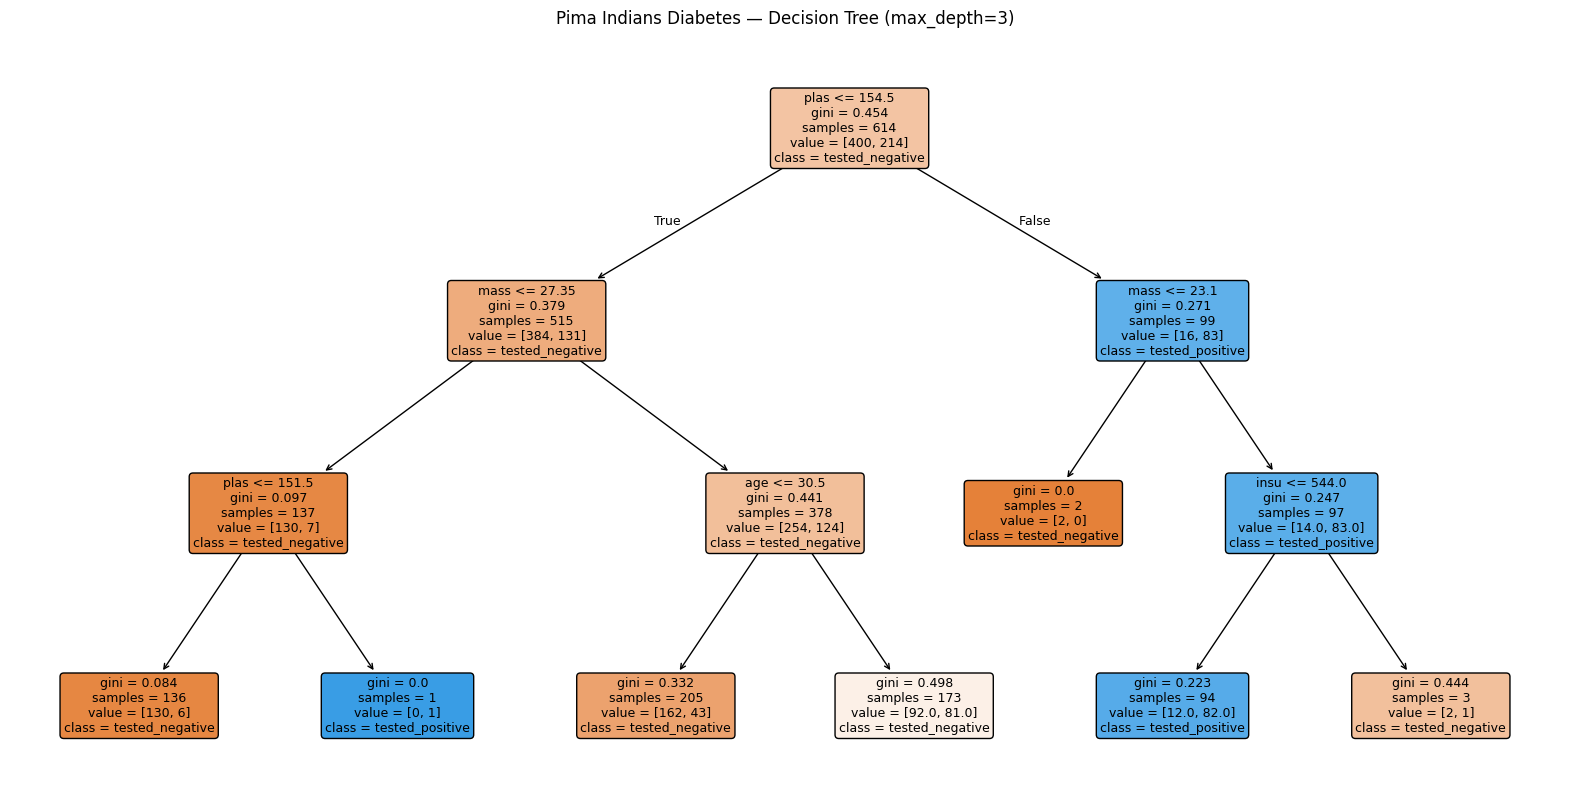


Top 3 important features:
plas    0.642563
mass    0.201094
age     0.137775
dtype: float64


In [13]:
plt.figure(figsize=(20, 10))
plot_tree(
    tree_depth3,
    feature_names=X.columns,
    class_names=[str(c) for c in tree_depth3.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Pima Indians Diabetes — Decision Tree (max_depth=3)")
plt.show()

# Print the 3 most important features
importances = pd.Series(
    tree_depth3.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 3 important features:")
print(importances.head(3))

# Compare Gini and entropy


In [15]:
tree_entropy = DecisionTreeClassifier(
    max_depth=3,
    criterion="entropy",
    random_state=0
)
tree_entropy.fit(X_train, y_train)

entropy_test_acc = accuracy_score(
    y_test, tree_entropy.predict(X_test)
)

print("Gini test accuracy:", test_acc_3)
print("Entropy test accuracy:", entropy_test_acc)

Gini test accuracy: 0.6948051948051948
Entropy test accuracy: 0.6948051948051948
